# Project 24: Privacy-Preserving Data Sharing Pipeline

Analisis Q1-Q12. Semua tabel dibaca dari `results/` (hasil skrip Python dan SQL). Data adalah simulasi dengan identitas palsu (Faker); data asli, mapping key, dan kunci HMAC tidak ada di repo.

In [1]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd()
while not (ROOT / 'results').exists():
    ROOT = ROOT.parent
R = lambda f: pd.read_csv(next((ROOT / 'results' / d / f) for d in ('1-data-preparation', '2-analysis', '3-presentation') if (ROOT / 'results' / d / f).exists()))
pd.options.display.float_format = '{:.6g}'.format
pd.options.display.max_colwidth = 80
plt.rcParams.update({'figure.figsize': (9, 3.4), 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, GREY, ORANGE = '#1A73E8', '#9AA0A6', '#E8710A'

## Q1. Klasifikasi kolom
Setiap kolom diklasifikasi (identitas langsung, quasi-identifier, sensitif, aman) dan diberi metode. Kebijakan lengkap: `config/column_policy.yaml`.

In [2]:
display(R('column_classification.csv')[['table','column','class','method','output','rows_with_identity']]); R('data_profile.csv')

,table,column,class,method,output,rows_with_identity
0,production,date,quasi,generalize,week,NaN
1,production,shift,quasi,keep,shift,NaN
2,production,station,quasi,keep,station,NaN
3,production,model,quasi,keep,model,NaN
4,production,employee_id,direct,drop,(dihapus),4500
5,production,operator_name,direct,pseudonymize,operator_code,4500
6,production,lot_no,direct,mapping_key,lot_code,1500
7,production,customer_name,direct,drop,(dihapus),4500
8,production,input_qty,sensitive,scale,input_index,NaN
9,production,ng_qty,sensitive,scale,ng_index,NaN


,item,value
0,baris produksi,4500
1,baris defect_log,6313
2,hari kerja,75
3,operator (orang),39
4,string nama operator berbeda,115
5,baris dengan penulisan nama kotor,127
6,customer,12
7,lot,450
8,baris model khusus,1500
9,baris model khusus dengan nama customer di kode lot,1500


## Q2. Baris unik dan k minimum, sebelum vs sesudah

In [3]:
R('risk_k_anonymity.csv')

,combo,columns,n_rows,groups_before,pct_unique_before,k_min_before,groups_after,pct_unique_after,k_min_after,k_target_met
0,QI dasar,shift + station + model,4500,60,0,75,60,0,75,True
1,QI + waktu,tanggal/minggu + shift + station + model,4500,4500,1,1,900,0,5,True
2,QI + waktu + operator (terketat),tanggal/minggu + shift + station + model + operator,4500,4500,1,1,900,0,5,True


## Q3. Serangan kamus: hash biasa vs HMAC

In [4]:
R('risk_dictionary_attack.csv')

,scheme,candidates,operators_attacked,recovered,recovery_rate
0,SHA-256 tanpa kunci (hash biasa),19462,39,39,1
1,"HMAC-SHA256 dengan kunci rahasia, penyerang memakai hash biasa",19462,38,0,0
2,"HMAC-SHA256 dengan kunci rahasia, penyerang menebak 6 kunci umum",116772,38,0,0


## Q4. Catatan bebas: sisa nama dan telepon menurut cara pembersihan

In [5]:
display(R('risk_notes.csv')); R('risk_text_scan.csv')

,method,rows,rows_with_identity,rows_phone,rows_name,rows_customer,rows_text_unchanged
0,Tanpa pembersihan (data asli),4500,142,96,101,46,4500
1,Regex: telepon + nama lengkap + customer yang dikenal,4500,21,0,21,0,4358
2,Allowlist frasa aman (dipakai pipeline),4500,0,0,0,0,4358


,stage,table,text_columns,name_hits,phone_hits,employee_id_hits,customer_hits,rows_hit
0,sebelum,production,"date,shift,station,model,employee_id,operator_name,lot_no,customer_name,note",5901,96,4500,5606,14902
1,sebelum,defect_log,"date,shift,station,model,defect_code",0,0,0,0,0
2,sesudah,production,"week,shift,station,model,operator_code,lot_code,note_clean",0,0,0,0,0
3,sesudah,defect_log,"week,shift,station,model,defect_code",0,0,0,0,0


## Risiko sisa: sel stasiun x shift dan penyambungan dengan daftar jaga

In [6]:
display(R('risk_operator_cells.csv').query('operators_before == 1')); R('risk_linkage.csv')

,station,shift,operators_before,codes_visible_after,masked,single_person_identifiable_before,single_person_identifiable_after
15,Performance Test (Dyno),Shift 2,1,0,True,True,False


,attacker_knowledge,operators,codes_linked_before,codes_linked_after,rate_before,rate_after
0,Tahu satu-satunya orang di sel stasiun x shift (tanpa minggu),39,1,0,0.025641,0
1,Tahu daftar jaga mingguan lengkap (stasiun x shift x minggu),39,39,38,1,0.974359


## Q5. KPI, ranking stasiun, dan Pareto: asli vs anonim

In [7]:
display(R('utility_kpi.csv').head(7)); display(R('utility_station_ranking.csv').head(3)); R('utility_pareto.csv').head(5)

,kpi,raw,anon,abs_diff,same
0,Yield lini (seluruh periode),0.882581,0.882581,7.49319e-10,True
1,"Yield lini, model = Bebek 125",0.881374,0.881374,7.92379e-10,True
2,"Yield lini, model = Matic 110",0.900142,0.900142,5.09675e-10,True
3,"Yield lini, model = Sport 150",0.849475,0.849475,1.15462e-09,True
4,"Yield lini, shift = Shift 1",0.881286,0.881286,6.97202e-10,True
5,"Yield lini, shift = Shift 2",0.883878,0.883878,8.01512e-10,True
6,NG rate stasiun Frame Painting,0.031664,0.031664,9.30762e-11,True


,rank,station_raw,ng_rate_raw,station_anon,ng_rate_anon,same_station
0,1,Frame Painting,0.031664,Frame Painting,0.031664,True
1,2,Electrical Test,0.0143046,Electrical Test,0.0143046,True
2,3,Performance Test (Dyno),0.0124933,Performance Test (Dyno),0.0124933,True


,rank,defect_raw,defect_name,qty_raw,share_raw,defect_anon,qty_index_anon,share_anon,same_defect,share_diff
0,1,PNT-01,Cat tipis,1444,0.118955,PNT-01,671.888,0.118955,True,1.86798e-08
1,2,PNT-02,Cat berkulit jeruk,1131,0.0931708,PNT-02,526.25,0.0931708,True,8.85311e-09
2,3,ELT-02,Starter gagal,722,0.0594777,ELT-02,335.944,0.0594777,True,9.30184e-10
3,4,FWD-01,Porositas las,714,0.0588187,FWD-01,332.221,0.0588187,True,1.12425e-09
4,5,BDY-01,Gores panel body,666,0.0548645,BDY-01,309.887,0.0548645,True,5.26458e-10


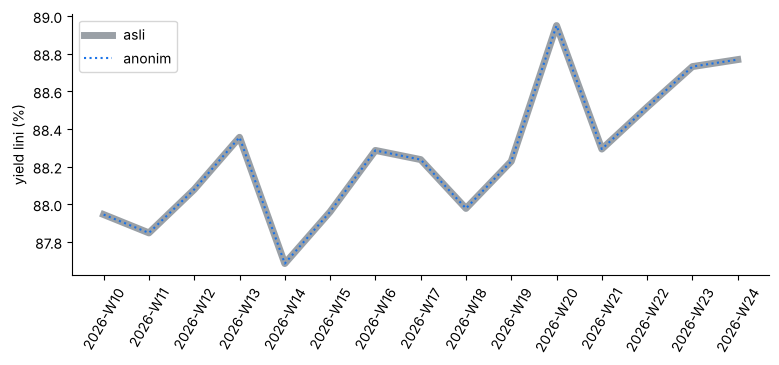

In [8]:
w = R('utility_weekly_yield.csv'); plt.plot(w.week, w.yield_raw * 100, color=GREY, lw=5, label='asli'); plt.plot(w.week, w.yield_anon * 100, color=BLUE, ls=':', label='anonim'); plt.xticks(rotation=60); plt.ylabel('yield lini (%)'); plt.legend(); plt.show()

## Q6. Tren dan korelasi setelah generalisasi tanggal dan skala angka

In [9]:
R('utility_trend.csv')

,metric,raw,anon
0,"Kemiringan tren yield lini, deret mingguan (poin persentase per minggu)",0.0608066,0.0608066
1,"Kemiringan tren yield lini, deret harian dikali 5 (asli) vs mingguan (anonim)",0.0609894,0.0608066
2,"Korelasi Pearson yield mingguan (asli mingguan = 1,0)",1,1
3,Korelasi Pearson input vs NG per baris,0.194018,0.194018
4,"Korelasi Pearson NG rate stasiun x model (asli = 1,0)",1,1
5,"Yield lini terendah (asli: harian, anonim: mingguan)",0.856278,0.876854
6,"Yield lini tertinggi (asli: harian, anonim: mingguan)",0.910638,0.8895
7,Jumlah titik waktu untuk tren,75,15


## Q7. Kurva risiko vs utilitas menurut tingkat generalisasi

,granularity,time_points,pct_unique,k_min,k_median,trend_corr_weekly,max_abs_error_yield,k_target_met
0,Harian,75,1,1,1,1,0,False
1,Mingguan,15,0,5,5,1,0,True
2,Dua mingguan,8,0,5,5,0.899078,0.00329098,True
3,Bulanan,4,0,5,10,0.797875,0.00418196,True
4,Seluruh periode,1,0,35,40,0,0.00691926,True


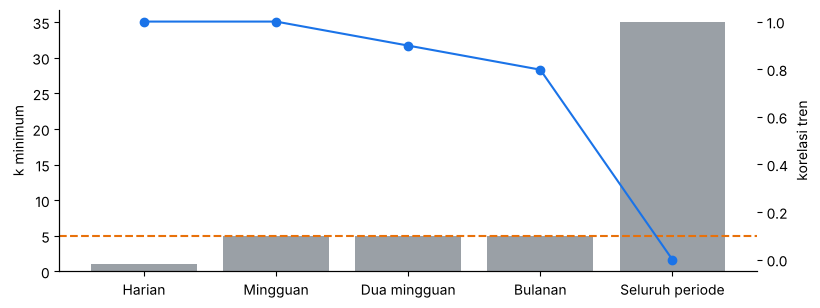

In [10]:
g = R('granularity_curve.csv'); display(g)
fig, ax = plt.subplots(); ax.bar(g.granularity, g.k_min, color=GREY); ax.axhline(5, color=ORANGE, ls='--'); ax.set_ylabel('k minimum')
ax2 = ax.twinx(); ax2.plot(g.granularity, g.trend_corr_weekly, color=BLUE, marker='o'); ax2.set_ylabel('korelasi tren'); plt.show()

## Q8. Trade-off tiap metode

In [11]:
R('method_tradeoff.csv')[['method','risk_measure','risk_before','risk_after','utility_measure','utility_value','reversible']]

,method,risk_measure,risk_before,risk_after,utility_measure,utility_value,reversible
0,Pseudonymization HMAC-SHA256 + kunci,Operator yang namanya pulih lewat serangan kamus (rasio),1,0,Orang yang punya tepat satu kode (rasio),1,Tidak tanpa daftar kode
1,Hash biasa SHA-256 tanpa kunci (pembanding),Operator yang namanya pulih lewat serangan kamus (rasio),1,1,Orang yang punya tepat satu kode (rasio),1,Tidak
2,Mapping key,Baris model khusus yang kode lotnya memuat nama customer,1500,0,Lot yang tetap bisa dibedakan (rasio),1,"Ya, oleh pemegang kunci"
3,Generalisasi tanggal ke minggu,Baris unik pada kombinasi terketat (rasio),1,0,Titik waktu tren yang tersisa (rasio terhadap harian),0.2,Tidak
4,Skala angka (indeks base 100),Nilai asli yang terhitung bila satu nilai asli diketahui (rasio),1,1,Selisih yield lini (poin),7.49319e-10,"Ya, dengan nilai dasar"
5,Hapus kolom identitas,Nilai identitas langsung yang tersisa (jumlah baris x kolom),9000,0,Kolom yang dihapus (jumlah),2,Tidak
6,Bersihkan catatan: allowlist frasa aman,"Catatan dengan nama, telepon, atau customer (baris)",142,0,Catatan yang berubah (rasio baris),0.0315556,Tidak
7,Bersihkan catatan: regex nama dan telepon (pembanding),"Catatan dengan nama, telepon, atau customer (baris)",142,21,Catatan yang berubah (rasio baris),0.0315556,Tidak
8,Tutup kode operator di sel satu orang,Sel stasiun x shift yang menunjuk satu orang,1,0,Baris tanpa kode operator (rasio),0.05,Tidak


## Q9 dan Q12. Deterministik dan pemulihan mapping key

In [12]:
display(R('validation_checks.csv')); R('validation_name_normalization.csv')

,question,check,n_tested,n_pass,result
0,Q9,Output sama persis pada dua kali jalan dengan kunci yang sama (file anonim),2,2,lulus
1,Q9,Mapping key sama persis pada dua kali jalan dengan kunci yang sama,1,1,lulus
2,Q9,Kode operator berubah semua saat kunci diganti (baris dengan kode berbeda),4275,4275,lulus
3,Q9,Yield lini sama saat kunci diganti (selisih di bawah 1e-6),1,1,lulus
4,Q12,Kode lot dikembalikan ke nilai asli (baris),4500,4500,lulus
5,Q12,Kode operator terlihat dikembalikan ke nomor karyawan asli (baris),4275,4275,lulus
6,Q12,Indeks produksi dikembalikan ke jumlah asli dengan nilai dasar (baris x kolom),9000,9000,lulus
7,Q12,Indeks defect dikembalikan ke jumlah asli (baris),6313,6313,lulus
8,Q12,Lot lama tetap memakai kode lama saat ada file baru (lot),450,450,lulus
9,Q12,Lot baru mendapat kode baru yang tidak bentrok (lot),1,1,lulus


,scheme,distinct_codes,persons,persons_with_multiple_codes,max_codes_per_person
0,HMAC pada nama apa adanya,115,39,38,4
1,HMAC pada nama yang dinormalkan (dipakai pipeline),39,39,0,1


## Q10-Q11. Waktu yang dihemat (waktu manual dan jumlah file per tahun adalah asumsi)

In [13]:
display(R('impact_time.csv')); R('impact_scenarios.csv')

,item,value,unit,label
0,"Waktu pipeline per file (median 7 kali jalan, dibulatkan ke atas)",1,detik,measured
1,Baris yang diproses per file,4500,baris,measured
2,Waktu anonymization manual di Excel per file,45,menit,estimated
3,Menit yang digantikan per file,45,menit,estimated
4,File yang dibagikan per tahun,24,file,estimated
5,Jam kerja dihemat per tahun,18,jam,estimated


,manual_minutes_per_file,files_per_year,hours_saved_per_year,label
0,30,12,6,estimated
1,30,24,12,estimated
2,30,48,24,estimated
3,45,12,9,estimated
4,45,24,18,estimated
5,45,48,36,estimated
6,60,12,12,estimated
7,60,24,24,estimated
8,60,48,48,estimated


## Cek silang SQL vs pandas dan pemindaian berkas rahasia

In [14]:
x = R('crosscheck_sql.csv'); print(f"{int(x.match.sum())} dari {len(x)} pemeriksaan cocok"); R('secret_scan.csv')

26 dari 26 pemeriksaan cocok


,check,scope,n_checked,hits,result
0,Berkas rahasia ikut dilacak atau akan ikut di-commit,80 berkas,80,0,lulus
1,Berkas rahasia tidak diabaikan .gitignore,5 berkas rahasia yang ada,5,0,lulus
2,Berkas rahasia pernah masuk riwayat commit,"5 commit, semua cabang",5,0,lulus
3,nama operator muncul di berkas repo,80 berkas x 39 nilai,80,0,lulus
4,nomor karyawan muncul di berkas repo,80 berkas x 39 nilai,80,0,lulus
5,nama customer muncul di berkas repo,80 berkas x 12 nilai,80,0,lulus
6,nomor telepon muncul di berkas repo,80 berkas x 96 nilai,80,0,lulus
7,kunci HMAC muncul di berkas repo,80 berkas x 1 nilai,80,0,lulus
